In [5]:
import sys
!{sys.executable} -m pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.0 MB 2.2 MB/s eta 0:00:01
     |████████████████████████████████| 233 kB 1.3 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [6]:
#EXPERIMENT 8 
#Peform Analysis of Variance (ANOVA) on Iris Dataset 

In [8]:
#1.Import requires Libraries 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.datasets import load_iris
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [ ]:
#2. Load Iris Dataset

In [17]:
iris=load_iris()

#Create DataFrame
df=pd.DataFrame(
   iris.data,
   columns=[
      "sepal_length",
      "sepal_width",
      "petal_length",
      "petal_width"
   ]
)
#Add target/species column 
df["target"]=iris.target

# Convert numerical target into species names
df["species"] = df["target"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})


In [20]:
#3. Display Dataset

In [21]:
print("First 5 records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

First 5 records:
   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  Setosa
1           4.9          3.0           1.4          0.2       0  Setosa
2           4.7          3.2           1.3          0.2       0  Setosa
3           4.6          3.1           1.5          0.2       0  Setosa
4           5.0          3.6           1.4          0.2       0  Setosa

Dataset Shape:
(150, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
 5   species       150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.

In [ ]:
#4. Visualize Iris Dataset

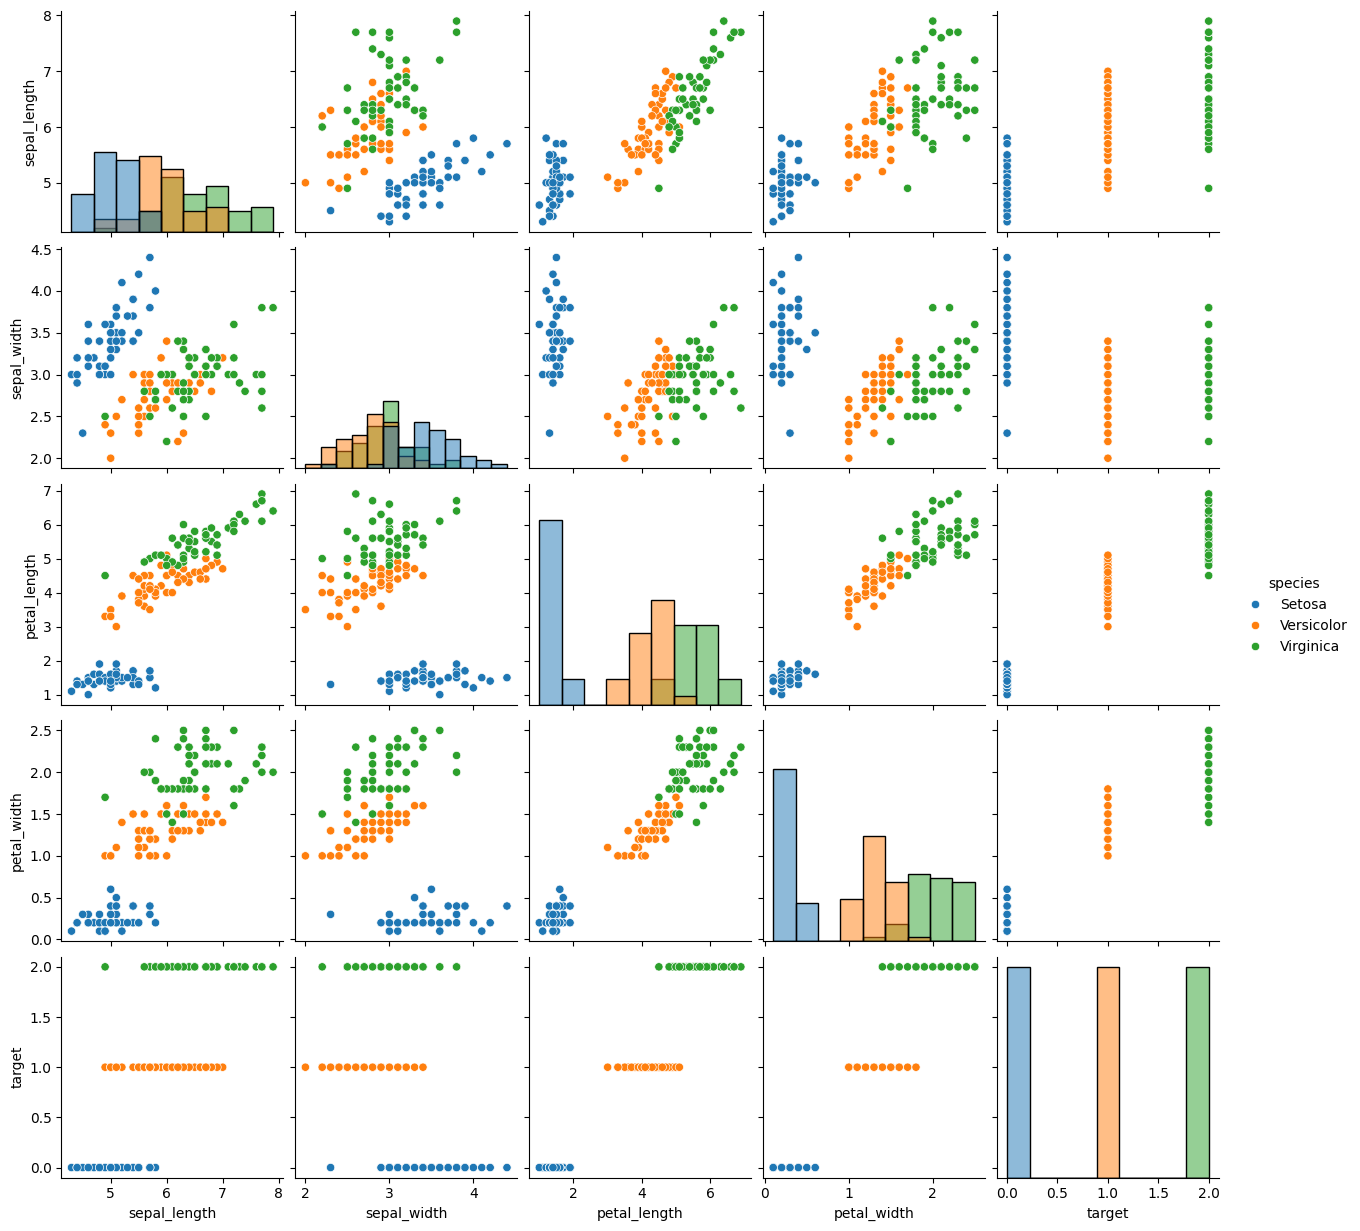

In [22]:
sns.pairplot(
   df,
   hue="species",
   diag_kind="hist"
)

plt.show()

In [ ]:
#5. Calculate Mean Sepal Width for Each Species

In [24]:
print("\nMean Sepal Width by Species:")

mean_values = df.groupby("species")["sepal_width"].mean()

print(mean_values)


Mean Sepal Width by Species:
species
Setosa        3.428
Versicolor    2.770
Virginica     2.974
Name: sepal_width, dtype: float64


In [ ]:
#6. Check Normality using Shapiro-Wilk Test 

In [25]:
print("\nShapiro-Wilk Normality Test:")
for species in df ["species"].unique():
   data= df[df["species"]==species]["sepal_width"]

   statistic,p_value=stats.shapiro(data)

   print(
      f"{species}:"
      f"Statisitc={statistic:4f},"
      f"P-value={p_value:4f}"
   )


Shapiro-Wilk Normality Test:
Setosa:Statisitc=0.971720,P-value=0.271526
Versicolor:Statisitc=0.974133,P-value=0.337995
Virginica:Statisitc=0.967391,P-value=0.180896


In [ ]:
#7. Check Equality of variances using Levene's Test

sentosa=df[df["species"]=="Setosa"]["sepal_width"]

versicolor